In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
file_path = r"C:\Users\Dell\Desktop\Analytics Platform\ecommerce_features.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (2000, 21)


,Order ID,Customer ID,Product ID,Product Name,Product Category,Quantity,Price (INR),Discount (%),Order Date,Customer Location,...,Review,Sales/Revenue (INR),Year,Month,Month Name,Quarter,Day of Week,Discount Amount (INR),Gross Sales (INR),Calculated Revenue (INR)
0,ORD00091,CUST1105,P009,Sneakers,Clothing,5,2907.60,25,2023-09-23,Hyderabad,...,Very disappointing purchase,10903.50,2023,9,September,3,Saturday,3634.5000,14538.00,10903.5000
1,ORD00210,CUST1064,P005,Laptop,Electronics,3,52234.91,15,2024-12-26,Chandigarh,...,Not very satisfied with the product,133199.02,2024,12,December,4,Thursday,23505.7095,156704.73,133199.0205
2,ORD00105,CUST1006,P010,Kurta,Clothing,4,1000.22,20,2026-02-23,Gurugram,...,"Below average, needs improvement",3200.70,2026,2,February,1,Monday,800.1760,4000.88,3200.7040
3,ORD00244,CUST1087,P008,Jacket,Clothing,5,2515.47,5,2023-12-16,Gurugram,...,Not very satisfied with the product,11948.48,2023,12,December,4,Saturday,628.8675,12577.35,11948.4825
4,ORD00014,CUST1119,P015,Table Lamp,Home & Kitchen,3,983.81,0,2021-03-30,Mumbai,...,"Amazing product, highly recommended",2951.43,2021,3,March,1,Tuesday,0.0000,2951.43,2951.4300


In [3]:
# Check required column 

required_columns = [
    "Customer ID",
    "Product ID",
    "Product Name"
]

print("Checking required columns...\n")

for column in required_columns:
    if column in df.columns:
        print(f"{column}: Available")
    else:
        print(f"{column}: NOT AVAILABLE")

Checking required columns...

Customer ID: Available
Product ID: Available
Product Name: Available


In [4]:
# Check missing values

print("Missing values:")

print(
    df[required_columns].isnull().sum()
)

Missing values:
Customer ID     0
Product ID      0
Product Name    0
dtype: int64


In [5]:
# Count customer and products

number_of_customers = df["Customer ID"].nunique()
number_of_products = df["Product ID"].nunique()

print("Unique Customers:", number_of_customers)
print("Unique Products:", number_of_products)

Unique Customers: 102
Unique Products: 30


In [6]:
print(
    "Unique Product Names:",
    df["Product Name"].nunique()
)

Unique Product Names: 30


In [7]:
# Examine customer - products interactions

interaction_data = df[
    [
        "Customer ID",
        "Product ID",
        "Product Name"
    ]
].dropna()

print("Total transaction interactions:", len(interaction_data))

print(
    "Unique customer-product interactions:",
    interaction_data[
        ["Customer ID", "Product ID"]
    ].drop_duplicates().shape[0]
)

Total transaction interactions: 2000
Unique customer-product interactions: 243


In [8]:
# Check Purchases per customer

customer_interactions = (
    interaction_data
    .groupby("Customer ID")["Product ID"]
    .nunique()
)

print("Average products per customer:",
      round(customer_interactions.mean(), 2))

print("Median products per customer:",
      customer_interactions.median())

print("Maximum products purchased by one customer:",
      customer_interactions.max())

Average products per customer: 2.38
Median products per customer: 2.0
Maximum products purchased by one customer: 7


In [9]:
customer_interactions.describe()

count    102.000000
mean       2.382353
std        1.219025
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max        7.000000
Name: Product ID, dtype: float64

In [10]:
# Check repeat purchases

customers_multiple_products = (
    customer_interactions > 1
).sum()

customers_one_product = (
    customer_interactions == 1
).sum()

print(
    "Customers who purchased multiple products:",
    customers_multiple_products
)

print(
    "Customers who purchased only one product:",
    customers_one_product
)

Customers who purchased multiple products: 75
Customers who purchased only one product: 27


In [11]:
percentage_multiple = (
    customers_multiple_products /
    number_of_customers
) * 100

print(
    "Percentage of customers with multiple products:",
    round(percentage_multiple, 2),
    "%"
)

Percentage of customers with multiple products: 73.53 %


In [12]:
# Check repeat customer-product interactions

customer_product_counts = (
    df.groupby(
        ["Customer ID", "Product ID"]
    )
    .size()
    .reset_index(name="Purchase_Count")
)

customer_product_counts.head(10)

,Customer ID,Product ID,Purchase_Count
0,CUST1001,P003,11
1,CUST1001,P006,6
2,CUST1001,P015,7
3,CUST1001,P023,11
4,CUST1002,P011,9
5,CUST1002,P013,7
6,CUST1003,P008,11
7,CUST1004,P005,7
8,CUST1004,P016,9
9,CUST1004,P021,7


In [13]:
repeat_purchases = customer_product_counts[
    customer_product_counts["Purchase_Count"] > 1
]

print(
    "Repeated customer-product combinations:",
    len(repeat_purchases)
)

print(
    "Total customer-product combinations:",
    len(customer_product_counts)
)

Repeated customer-product combinations: 243
Total customer-product combinations: 243


In [14]:
# Create the customer * product matrix

interaction_matrix = pd.pivot_table(
    df,
    index="Customer ID",
    columns="Product ID",
    values="Order ID",
    aggfunc="count",
    fill_value=0
)

print("Interaction matrix shape:")
print(interaction_matrix.shape)

interaction_matrix.head()

Interaction matrix shape:
(102, 30)


Product ID,P001,P002,P003,P004,P005,P006,P007,P008,P009,P010,...,P021,P022,P023,P024,P025,P026,P027,P028,P029,P030
Customer ID,,,,,,,,,,,,,,,,,,,,,
CUST1001,0,0,11,0,0,6,0,0,0,0,...,0,0,11,0,0,0,0,0,0,0
CUST1002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CUST1003,0,0,0,0,0,0,0,11,0,0,...,0,0,0,0,0,0,0,0,0,0
CUST1004,0,0,0,0,7,0,0,0,0,0,...,7,0,0,0,0,0,0,7,0,0
CUST1005,0,5,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [15]:
# Calculated interaction sparsity

total_cells = (
    interaction_matrix.shape[0] *
    interaction_matrix.shape[1]
)

non_zero_cells = (
    interaction_matrix != 0
).sum().sum()

sparsity = (
    1 -
    (non_zero_cells / total_cells)
) * 100

print("Total possible customer-product interactions:",
      total_cells)

print("Actual interactions:",
      non_zero_cells)

print("Sparsity:",
      round(sparsity, 2),
      "%")

Total possible customer-product interactions: 3060
Actual interactions: 243
Sparsity: 92.06 %


In [16]:
# Check product popularity

product_popularity = (
    df.groupby("Product ID")
    .size()
    .sort_values(ascending=False)
)

print("Most purchased products:")
print(product_popularity.head(10))

Most purchased products:
Product ID
P021    110
P016    109
P028     99
P025     98
P030     98
P003     91
P011     84
P008     80
P007     79
P002     77
dtype: int64


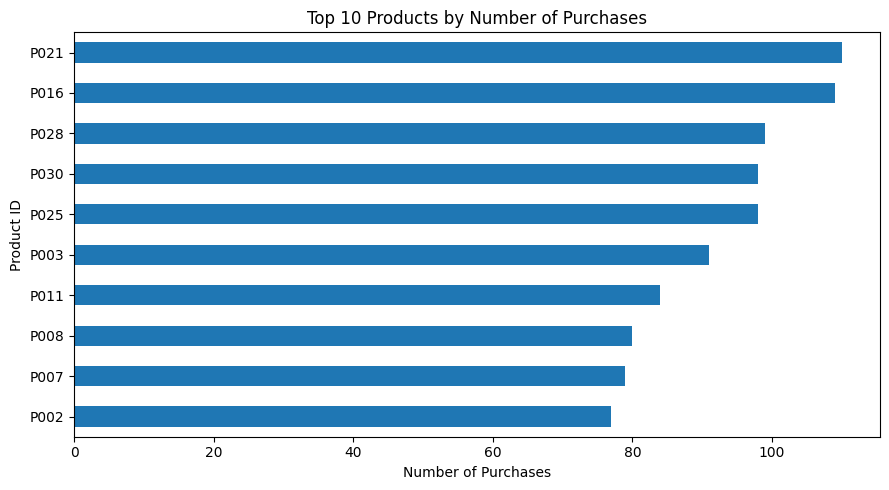

In [17]:
# Visulazie product popularity

product_popularity.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Top 10 Products by Number of Purchases")
plt.xlabel("Number of Purchases")
plt.ylabel("Product ID")

plt.tight_layout()
plt.show()

In [18]:
# Check customer activity

customer_activity = (
    df.groupby("Customer ID")
    .size()
    .sort_values(ascending=False)
)

print("Most active customers:")
print(customer_activity.head(10))

Most active customers:
Customer ID
CUST1039    62
CUST1036    60
CUST1096    48
CUST1018    45
CUST1007    42
CUST1111    40
CUST1092    38
CUST1012    38
CUST1085    37
CUST1001    35
dtype: int64


In [19]:
customer_activity.describe()

count    102.000000
mean      19.607843
std       11.960460
min        3.000000
25%       11.000000
50%       16.500000
75%       27.000000
max       62.000000
dtype: float64

In [20]:
# Create a recommendation dataset

recommendation_data = (
    df[
        [
            "Customer ID",
            "Product ID",
            "Product Name"
        ]
    ]
    .dropna()
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Recommendation interaction dataset:")
print(recommendation_data.head())

print("\nShape:", recommendation_data.shape)

Recommendation interaction dataset:
  Customer ID Product ID Product Name
0    CUST1105       P009     Sneakers
1    CUST1064       P005       Laptop
2    CUST1006       P010        Kurta
3    CUST1087       P008       Jacket
4    CUST1119       P015   Table Lamp

Shape: (243, 3)


In [21]:
# Decision point

print("========== RECOMMENDATION DATA CHECK ==========")

print("Unique Customers:", number_of_customers)
print("Unique Products:", number_of_products)

print(
    "Unique Customer-Product Interactions:",
    len(customer_product_counts)
)

print(
    "Average Products per Customer:",
    round(customer_interactions.mean(), 2)
)

print(
    "Customers with Multiple Products:",
    customers_multiple_products
)

print(
    "Interaction Matrix:",
    interaction_matrix.shape
)

print(
    "Sparsity:",
    round(sparsity, 2),
    "%"
)

========== RECOMMENDATION DATA CHECK ==========
Unique Customers: 102
Unique Products: 30
Unique Customer-Product Interactions: 243
Average Products per Customer: 2.38
Customers with Multiple Products: 75
Interaction Matrix: (102, 30)
Sparsity: 92.06 %


In [22]:
# Create customer-product binary matrix

customer_product_matrix = pd.crosstab(
    df["Customer ID"],
    df["Product ID"]
)

print("Customer-Product Matrix:")
print(customer_product_matrix.shape)

customer_product_matrix.head()

Customer-Product Matrix:
(102, 30)


Product ID,P001,P002,P003,P004,P005,P006,P007,P008,P009,P010,...,P021,P022,P023,P024,P025,P026,P027,P028,P029,P030
Customer ID,,,,,,,,,,,,,,,,,,,,,
CUST1001,0,0,11,0,0,6,0,0,0,0,...,0,0,11,0,0,0,0,0,0,0
CUST1002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CUST1003,0,0,0,0,0,0,0,11,0,0,...,0,0,0,0,0,0,0,0,0,0
CUST1004,0,0,0,0,7,0,0,0,0,0,...,7,0,0,0,0,0,0,7,0,0
CUST1005,0,5,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [23]:
# Convert purchase counts into binary interactions

binary_matrix = (customer_product_matrix > 0).astype(int)

print("Binary Customer-Product Matrix:")
print(binary_matrix.shape)

binary_matrix.head()

Binary Customer-Product Matrix:
(102, 30)


Product ID,P001,P002,P003,P004,P005,P006,P007,P008,P009,P010,...,P021,P022,P023,P024,P025,P026,P027,P028,P029,P030
Customer ID,,,,,,,,,,,,,,,,,,,,,
CUST1001,0,0,1,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
CUST1002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
CUST1003,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
CUST1004,0,0,0,0,1,0,0,0,0,0,...,1,0,0,0,0,0,0,1,0,0
CUST1005,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [24]:
# Calculate product similarity 

from sklearn.metrics.pairwise import cosine_similarity

# Calculate product-to-product similarity
product_similarity = cosine_similarity(
    binary_matrix.T
)

# Convert to DataFrame
product_similarity_df = pd.DataFrame(
    product_similarity,
    index=binary_matrix.columns,
    columns=binary_matrix.columns
)

print("Product similarity matrix:")
print(product_similarity_df.shape)

product_similarity_df.head()

Product similarity matrix:
(30, 30)


Product ID,P001,P002,P003,P004,P005,P006,P007,P008,P009,P010,...,P021,P022,P023,P024,P025,P026,P027,P028,P029,P030
Product ID,,,,,,,,,,,,,,,,,,,,,
P001,1.000000,0.111111,0.000000,0.000000,0.0,0.000000,0.0,0.222222,0.136083,0.125988,...,0.089087,0.000000,0.235702,0.149071,0.096225,0.0,0.000000,0.000000,0.000000,0.201008
P002,0.111111,1.000000,0.000000,0.000000,0.0,0.166667,0.0,0.111111,0.000000,0.000000,...,0.000000,0.000000,0.117851,0.000000,0.000000,0.0,0.000000,0.096225,0.149071,0.100504
P003,0.000000,0.000000,1.000000,0.258199,0.0,0.158114,0.1,0.105409,0.000000,0.119523,...,0.169031,0.141421,0.111803,0.000000,0.182574,0.0,0.105409,0.273861,0.141421,0.000000
P004,0.000000,0.000000,0.258199,1.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.144338,0.000000,0.000000,0.0,0.136083,0.000000,0.000000,0.123091
P005,0.000000,0.000000,0.000000,0.000000,1.0,0.000000,0.0,0.117851,0.000000,0.000000,...,0.283473,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.306186,0.158114,0.000000


In [25]:
# Check product names

product_info = (
    df[["Product ID", "Product Name"]]
    .drop_duplicates()
)

product_info.head(10)

,Product ID,Product Name
0,P009,Sneakers
1,P005,Laptop
2,P010,Kurta
3,P008,Jacket
4,P015,Table Lamp
5,P004,Bluetooth Speaker
6,P020,Perfume
7,P016,Face Wash
8,P023,Yoga Mat
9,P026,Python Programming


In [26]:
# Create product id- product name mapping

product_name_map = (
    product_info
    .drop_duplicates("Product ID")
    .set_index("Product ID")["Product Name"]
    .to_dict()
)

print("Number of product mappings:", len(product_name_map))

product_name_map

Number of product mappings: 30


{'P009': 'Sneakers',
 'P005': 'Laptop',
 'P010': 'Kurta',
 'P008': 'Jacket',
 'P015': 'Table Lamp',
 'P004': 'Bluetooth Speaker',
 'P020': 'Perfume',
 'P016': 'Face Wash',
 'P023': 'Yoga Mat',
 'P026': 'Python Programming',
 'P030': 'Computer Networks',
 'P012': 'Cookware Set',
 'P025': 'Running Shoes',
 'P027': 'Data Science',
 'P007': 'Jeans',
 'P002': 'Smartphone',
 'P029': 'DBMS',
 'P028': 'Machine Learning',
 'P014': 'Water Bottle',
 'P018': 'Shampoo',
 'P017': 'Moisturizer',
 'P001': 'Wireless Headphones',
 'P003': 'Smartwatch',
 'P024': 'Badminton Racket',
 'P022': 'Football',
 'P013': 'Bedsheet',
 'P021': 'Cricket Bat',
 'P006': 'T-Shirt',
 'P011': 'Mixer Grinder',
 'P019': 'Sunscreen'}

In [29]:
# create a recommendation function

def recommend_similar_products(product_id, top_n=5):

    if product_id not in product_similarity_df.index:
        return pd.DataFrame(
            columns=[
                "Product ID",
                "Product Name",
                "Similarity Score"
            ]
        )

    similarity_scores = (
        product_similarity_df[product_id]
        .drop(product_id)
        .sort_values(ascending=False)
        .head(top_n)
    )

    recommendations = pd.DataFrame({
        "Product ID": similarity_scores.index,
        "Similarity Score": similarity_scores.values
    })

    recommendations["Product Name"] = (
        recommendations["Product ID"]
        .map(product_name_map)
    )

    return recommendations[
        [
            "Product ID",
            "Product Name",
            "Similarity Score"
        ]
    ]


In [28]:
# Text the recommendation system

print("Available Product IDs:")

print(
    sorted(
        binary_matrix.columns.tolist()
    )
)

Available Product IDs:
['P001', 'P002', 'P003', 'P004', 'P005', 'P006', 'P007', 'P008', 'P009', 'P010', 'P011', 'P012', 'P013', 'P014', 'P015', 'P016', 'P017', 'P018', 'P019', 'P020', 'P021', 'P022', 'P023', 'P024', 'P025', 'P026', 'P027', 'P028', 'P029', 'P030']


In [30]:
recommend_similar_products(
    "P003",
    top_n=5
)

,Product ID,Product Name,Similarity Score
0,P028,Machine Learning,0.273861
1,P004,Bluetooth Speaker,0.258199
2,P017,Moisturizer,0.210819
3,P025,Running Shoes,0.182574
4,P021,Cricket Bat,0.169031


In [31]:
# Check weither recommendations are meaningful

test_products = binary_matrix.columns[:5]

for product in test_products:

    print("\nProduct:", product)
    print("Product Name:", product_name_map.get(product))

    recommendations = recommend_similar_products(
        product,
        top_n=3
    )

    print(recommendations)


Product: P001
Product Name: Wireless Headphones
  Product ID       Product Name  Similarity Score
0       P023           Yoga Mat          0.235702
1       P008             Jacket          0.222222
2       P030  Computer Networks          0.201008

Product: P002
Product Name: Smartphone
  Product ID Product Name  Similarity Score
0       P020      Perfume          0.272166
1       P006      T-Shirt          0.166667
2       P029         DBMS          0.149071

Product: P003
Product Name: Smartwatch
  Product ID       Product Name  Similarity Score
0       P028   Machine Learning          0.273861
1       P004  Bluetooth Speaker          0.258199
2       P017        Moisturizer          0.210819

Product: P004
Product Name: Bluetooth Speaker
  Product ID Product Name  Similarity Score
0       P017  Moisturizer          0.272166
1       P003   Smartwatch          0.258199
2       P023     Yoga Mat          0.144338

Product: P005
Product Name: Laptop
  Product ID      Product Name  Simi

In [32]:
# Create customer based recommendation

def recommend_for_customer(customer_id, top_n=5):

    if customer_id not in binary_matrix.index:
        return pd.DataFrame(
            columns=[
                "Product ID",
                "Product Name",
                "Recommendation Score"
            ]
        )

    purchased_products = binary_matrix.loc[
        customer_id
    ]

    purchased_products = purchased_products[
        purchased_products > 0
    ].index.tolist()

    if len(purchased_products) == 0:
        return pd.DataFrame(
            columns=[
                "Product ID",
                "Product Name",
                "Recommendation Score"
            ]
        )

    scores = pd.Series(
        0.0,
        index=binary_matrix.columns
    )

    for product in purchased_products:

        scores += product_similarity_df[product]

    # Remove products already purchased
    scores[purchased_products] = 0

    recommendations = (
        scores
        .sort_values(ascending=False)
        .head(top_n)
    )

    result = pd.DataFrame({
        "Product ID": recommendations.index,
        "Recommendation Score": recommendations.values
    })

    result["Product Name"] = (
        result["Product ID"]
        .map(product_name_map)
    )

    return result[
        [
            "Product ID",
            "Product Name",
            "Recommendation Score"
        ]
    ]

In [33]:
# text customer recommendation

print(
    binary_matrix.index.tolist()[:10]
)

['CUST1001', 'CUST1002', 'CUST1003', 'CUST1004', 'CUST1005', 'CUST1006', 'CUST1007', 'CUST1008', 'CUST1009', 'CUST1010']


In [34]:
recommend_for_customer(
    "CUST1001",
    top_n=5
)

,Product ID,Product Name,Recommendation Score
0,P024,Badminton Racket,0.789292
1,P004,Bluetooth Speaker,0.531636
2,P009,Sneakers,0.402536
3,P030,Computer Networks,0.352702
4,P001,Wireless Headphones,0.341112


In [35]:
# check the customer existing purchases

customer_id = "CUST1001"

purchased = df[
    df["Customer ID"] == customer_id
][
    [
        "Product ID",
        "Product Name"
    ]
].drop_duplicates()

print("Products already purchased:")
purchased

Products already purchased:


,Product ID,Product Name
28,P003,Smartwatch
96,P015,Table Lamp
228,P006,T-Shirt
229,P023,Yoga Mat


In [36]:
recommend_for_customer(
    customer_id,
    top_n=5
)

,Product ID,Product Name,Recommendation Score
0,P024,Badminton Racket,0.789292
1,P004,Bluetooth Speaker,0.531636
2,P009,Sneakers,0.402536
3,P030,Computer Networks,0.352702
4,P001,Wireless Headphones,0.341112


In [37]:
# Evaluate recommendation coverage

positive_similarity_counts = (
    (product_similarity_df > 0)
    .sum(axis=1) - 1
)

print("Products with at least one similar product:")

print(
    (positive_similarity_counts > 0).sum()
)

print(
    "Total products:",
    len(product_similarity_df)
)

Products with at least one similar product:
30
Total products: 30


In [38]:
# calculate average similarity

similarity_values = []

for product in product_similarity_df.index:

    values = (
        product_similarity_df.loc[product]
        .drop(product)
    )

    positive_values = values[values > 0]

    similarity_values.extend(
        positive_values.tolist()
    )

if len(similarity_values) > 0:

    print(
        "Average positive similarity:",
        round(np.mean(similarity_values), 4)
    )

    print(
        "Number of positive product relationships:",
        len(similarity_values)
    )

else:

    print(
        "No positive product relationships found."
    )

Average positive similarity: 0.1556
Number of positive product relationships: 384


In [39]:
recommend_for_customer(
    "YOUR_CUSTOMER_ID",
    top_n=5
)

,Product ID,Product Name,Recommendation Score


In [40]:
print(
    "Products with at least one similar product:",
    (positive_similarity_counts > 0).sum()
)

Products with at least one similar product: 30


In [41]:
# Text with actual customer

print("Available Customer IDs:")
print(binary_matrix.index.tolist())

Available Customer IDs:
['CUST1001', 'CUST1002', 'CUST1003', 'CUST1004', 'CUST1005', 'CUST1006', 'CUST1007', 'CUST1008', 'CUST1009', 'CUST1010', 'CUST1012', 'CUST1013', 'CUST1014', 'CUST1015', 'CUST1016', 'CUST1017', 'CUST1018', 'CUST1020', 'CUST1021', 'CUST1022', 'CUST1023', 'CUST1024', 'CUST1025', 'CUST1026', 'CUST1027', 'CUST1028', 'CUST1029', 'CUST1030', 'CUST1031', 'CUST1032', 'CUST1033', 'CUST1035', 'CUST1036', 'CUST1037', 'CUST1038', 'CUST1039', 'CUST1040', 'CUST1041', 'CUST1042', 'CUST1043', 'CUST1044', 'CUST1045', 'CUST1046', 'CUST1047', 'CUST1049', 'CUST1050', 'CUST1051', 'CUST1055', 'CUST1056', 'CUST1057', 'CUST1058', 'CUST1060', 'CUST1061', 'CUST1062', 'CUST1063', 'CUST1064', 'CUST1065', 'CUST1066', 'CUST1067', 'CUST1068', 'CUST1069', 'CUST1070', 'CUST1072', 'CUST1073', 'CUST1074', 'CUST1075', 'CUST1076', 'CUST1077', 'CUST1080', 'CUST1081', 'CUST1082', 'CUST1083', 'CUST1084', 'CUST1085', 'CUST1087', 'CUST1088', 'CUST1089', 'CUST1090', 'CUST1092', 'CUST1093', 'CUST1094', 'CU

In [42]:
customer_id = "CUST1001"

print("Customer:", customer_id)

print("\nAlready Purchased:")
print(
    df[df["Customer ID"] == customer_id][
        ["Product ID", "Product Name"]
    ].drop_duplicates()
)

print("\nRecommended Products:")
print(
    recommend_for_customer(
        customer_id,
        top_n=5
    )
)

Customer: CUST1001

Already Purchased:
    Product ID Product Name
28        P003   Smartwatch
96        P015   Table Lamp
228       P006      T-Shirt
229       P023     Yoga Mat

Recommended Products:
  Product ID         Product Name  Recommendation Score
0       P024     Badminton Racket              0.789292
1       P004    Bluetooth Speaker              0.531636
2       P009             Sneakers              0.402536
3       P030    Computer Networks              0.352702
4       P001  Wireless Headphones              0.341112


In [43]:
# Check recommendation scores

recommendations = recommend_for_customer(
    customer_id,
    top_n=5
)

print(recommendations)

  Product ID         Product Name  Recommendation Score
0       P024     Badminton Racket              0.789292
1       P004    Bluetooth Speaker              0.531636
2       P009             Sneakers              0.402536
3       P030    Computer Networks              0.352702
4       P001  Wireless Headphones              0.341112


In [44]:
# Make sure already purchased products are not recommend

purchased_products = set(
    df[df["Customer ID"] == customer_id]["Product ID"]
)

recommended_products = set(
    recommendations["Product ID"]
)

overlap = purchased_products.intersection(
    recommended_products
)

print("Already purchased products:", purchased_products)
print("Recommended products:", recommended_products)
print("Overlap:", overlap)

Already purchased products: {'P006', 'P023', 'P015', 'P003'}
Recommended products: {'P009', 'P030', 'P004', 'P024', 'P001'}
Overlap: set()


In [45]:
# Generate recommendations for multiple customers

test_customers = binary_matrix.index[:10]

for customer in test_customers:

    recommendations = recommend_for_customer(
        customer,
        top_n=3
    )

    print("\nCustomer:", customer)

    if len(recommendations) > 0:
        print(
            recommendations[
                ["Product ID", "Product Name", "Recommendation Score"]
            ].to_string(index=False)
        )
    else:
        print("No recommendations available.")


Customer: CUST1001
Product ID      Product Name  Recommendation Score
      P024  Badminton Racket              0.789292
      P004 Bluetooth Speaker              0.531636
      P009          Sneakers              0.402536

Customer: CUST1002
Product ID Product Name  Recommendation Score
      P018      Shampoo              0.353553
      P010        Kurta              0.259619
      P019    Sunscreen              0.235702

Customer: CUST1003
Product ID        Product Name  Recommendation Score
      P001 Wireless Headphones              0.222222
      P017         Moisturizer              0.222222
      P014        Water Bottle              0.192450

Customer: CUST1004
Product ID Product Name  Recommendation Score
      P013     Bedsheet              0.527848
      P003   Smartwatch              0.442892
      P010        Kurta              0.438756

Customer: CUST1005
Product ID Product Name  Recommendation Score
      P018      Shampoo              0.353553
      P020      Perfume 

In [46]:
# Create final recommendation dataset

all_recommendations = []

for customer in binary_matrix.index:

    recommendations = recommend_for_customer(
        customer,
        top_n=5
    )

    if len(recommendations) > 0:

        recommendations = recommendations.copy()

        recommendations["Customer ID"] = customer

        all_recommendations.append(
            recommendations
        )

all_recommendations_df = pd.concat(
    all_recommendations,
    ignore_index=True
)

all_recommendations_df = all_recommendations_df[
    [
        "Customer ID",
        "Product ID",
        "Product Name",
        "Recommendation Score"
    ]
]

print("Total recommendations generated:",
      len(all_recommendations_df))

all_recommendations_df.head(20)

Total recommendations generated: 510


,Customer ID,Product ID,Product Name,Recommendation Score
0,CUST1001,P024,Badminton Racket,0.789292
1,CUST1001,P004,Bluetooth Speaker,0.531636
2,CUST1001,P009,Sneakers,0.402536
3,CUST1001,P030,Computer Networks,0.352702
4,CUST1001,P001,Wireless Headphones,0.341112
5,CUST1002,P018,Shampoo,0.353553
6,CUST1002,P010,Kurta,0.259619
7,CUST1002,P019,Sunscreen,0.235702
8,CUST1002,P001,Wireless Headphones,0.228962
9,CUST1002,P017,Moisturizer,0.228962


In [47]:
# Save recommendations

os.makedirs(r"C:\Users\Dell\Desktop\Analytics Platform", exist_ok=True)

In [48]:
all_recommendations_df.to_csv(
    r"C:\Users\Dell\Desktop\Analytics Platform\product_recommendations.csv",
    index=False
)

print("Recommendations saved successfully!")
print(
    r"C:\Users\Dell\Desktop\Analytics Platform\product_recommendations.csv"
)

Recommendations saved successfully!
C:\Users\Dell\Desktop\Analytics Platform\product_recommendations.csv


In [52]:
# Save the recommendation model data

import pickle

recommendation_model = {
    "product_similarity": product_similarity_df,
    "product_name_map": product_name_map,
    "binary_matrix": binary_matrix
}

os.makedirs(r"C:\Users\Dell\Desktop\Analytics Platform", exist_ok=True)

model_path = r"C:\Users\Dell\Desktop\Analytics Platform\product_recommendation.pkl"

with open(model_path, "wb") as file:
    pickle.dump(
        recommendation_model,
        file
    )

print("Recommendation model data saved!")
print(model_path)

Recommendation model data saved!
C:\Users\Dell\Desktop\Analytics Platform\product_recommendation.pkl


In [55]:
# Verify the saved model

print(
    "Recommendation model exists:",
    os.path.exists(
        r"C:\Users\Dell\Desktop\Analytics Platform\product_recommendation.pkl"
    )
)

print(
    "Recommendation results exist:",
    os.path.exists(
        r"C:\Users\Dell\Desktop\Analytics Platform\product_recommendations.csv"
    )
)

Recommendation model exists: True
Recommendation results exist: True


In [54]:
# Save the product similarity

product_similarity_df.to_csv(
    r"C:\Users\Dell\Desktop\Analytics Platform\product_similarity.csv"
)

print("Product similarity matrix saved!")

Product similarity matrix saved!
